# 02 - Baselines and Data Preparation

**Goal:** Prepare the data for modeling and build baseline models that the neural network must beat.

**Steps:**
1. Shift labels from 1-7 to 0-6 (needed by Keras sparse loss)
2. Stratified train/dev/test split (80/10/10)
3. Standardize the 10 numeric features (fit on train only)
4. Save the processed data for the next notebook
5. Train and compare: majority class, Logistic Regression, Random Forest

**Main metric:** macro F1 (plus per-class recall), because the classes are imbalanced. All models are evaluated on the **dev set**. The test set stays untouched until the final evaluation.

## 0. Setup

In [23]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import joblib
import numpy as np
import pandas as pd
from src.data import load_covertype, numeric_cols, target_col

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from src.evaluate import evaluate, plot_confusion

In [24]:
out_dir = "../data/processed/"
SEED = 42

## 1. Load the data

The loading code and column names are in `src/data.py`.

In [25]:
df = load_covertype()
df.shape

(581012, 55)

## 2. Features, labels and split

The original labels are 1 to 7. I subtract 1 so they become 0 to 6, which is what Keras expects with `sparse_categorical_crossentropy`. In the reports below, class 0 means `Cover_Type` 1, class 1 means `Cover_Type` 2, and so on.

The split is done in two steps (80% train, then the remaining 20% is split into 10% dev and 10% test). `stratify` keeps the class proportions the same in all three sets, and a fixed seed makes it reproducible.

In [26]:
X = df.drop(target_col, axis=1)
y = df[target_col] - 1

In [27]:
y.unique()

array([4, 1, 0, 6, 2, 5, 3])

In [28]:
X_train, X_dt, y_train, y_dt = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
X_dev, X_test, y_dev, y_test = train_test_split(X_dt, y_dt, test_size=0.5, random_state=SEED, stratify=y_dt)

In [29]:
print(y_train.value_counts(normalize=True))
print(y_dev.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Cover_Type
1    0.487598
0    0.364606
2    0.061537
6    0.035301
5    0.029892
4    0.016338
3    0.004729
Name: proportion, dtype: float64
Cover_Type
1    0.487599
0    0.364606
2    0.061531
6    0.035301
5    0.029879
4    0.016351
3    0.004733
Name: proportion, dtype: float64
Cover_Type
1    0.487608
0    0.364600
2    0.061547
6    0.035300
5    0.029896
4    0.016333
3    0.004716
Name: proportion, dtype: float64


The class proportions are almost identical in train, dev and test, so the stratified split worked.

## 3. Normalization

Only the 10 numeric features are standardized. The 44 binary columns are left unchanged.

The scaler is **fit on the training set only**, then applied to dev and test. Fitting on all the data would leak information from dev/test into training (data leakage). The fitted scaler is saved to `models/` so it can be reused later (for example in the API).

In [30]:
scaler = StandardScaler()

X_train_s = X_train.copy()
X_dev_s = X_dev.copy()
X_test_s = X_test.copy()

X_train_s[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_dev_s[numeric_cols] = scaler.transform(X_dev[numeric_cols])
X_test_s[numeric_cols] = scaler.transform(X_test[numeric_cols])

joblib.dump(scaler, "../models/scaler.joblib")

['../models/scaler.joblib']

## 4. Save processed data

The scaled arrays (float32) and labels are saved in one compressed file, so the next notebook can load them directly without repeating the preprocessing.

In [31]:
np.savez_compressed(
    out_dir + "covtype_processed.npz",
    X_train=X_train_s.to_numpy(dtype="float32"),
    X_dev=X_dev_s.to_numpy(dtype="float32"),
    X_test=X_test_s.to_numpy(dtype="float32"),
    y_train=y_train.to_numpy(),
    y_dev=y_dev.to_numpy(),
    y_test=y_test.to_numpy(),
)

## 5. Baseline models

All models are trained on the training set and evaluated on the dev set.

1. **Majority class:** always predicts the most frequent class. It shows the minimum any real model must beat.
2. **Logistic Regression:** a linear model (like a neural network without hidden layers).
3. **Random Forest:** a strong tree-based model for tabular data.

In [32]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_s, y_train)

dummy_y_pred = dummy_model.predict(X_dev_s)

In [33]:
lr_model = LogisticRegression(max_iter=500, random_state=SEED)
lr_model.fit(X_train_s, y_train)

lr_y_pred = lr_model.predict(X_dev_s)

In [34]:
rf_model = RandomForestClassifier(n_jobs=-1, random_state=SEED)
rf_model.fit(X_train_s, y_train)

rf_y_pred = rf_model.predict(X_dev_s)

## 6. Evaluation on the dev set

In [35]:
results = [
    evaluate("Majority class", y_dev, dummy_y_pred),
    evaluate("Logistic Regression", y_dev, lr_y_pred),
    evaluate("Random Forest", y_dev, rf_y_pred),
]

results_df = pd.DataFrame(results)
results_df.to_csv("../results/results_df.csv",index=False)
results_df

=== Majority class ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00     21184
           1       0.49      1.00      0.66     28330
           2       0.00      0.00      0.00      3575
           3       0.00      0.00      0.00       275
           4       0.00      0.00      0.00       950
           5       0.00      0.00      0.00      1736
           6       0.00      0.00      0.00      2051

    accuracy                           0.49     58101
   macro avg       0.07      0.14      0.09     58101
weighted avg       0.24      0.49      0.32     58101

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.71      0.70      0.71     21184
           1       0.75      0.80      0.77     28330
           2       0.68      0.81      0.74      3575
           3       0.58      0.39      0.47       275
           4       0.15      0.01      0.01       950
           5       0.50    

              precision    recall  f1-score   support

           0       0.96      0.94      0.95     21184
           1       0.95      0.97      0.96     28330
           2       0.94      0.96      0.95      3575
           3       0.92      0.83      0.87       275
           4       0.95      0.77      0.85       950
           5       0.93      0.89      0.91      1736
           6       0.97      0.96      0.96      2051

    accuracy                           0.95     58101
   macro avg       0.95      0.90      0.92     58101
weighted avg       0.95      0.95      0.95     58101



,model,accuracy,macro_f1
0,Majority class,0.487599,0.093650
1,Logistic Regression,0.724652,0.525898
2,Random Forest,0.953719,0.923118


**Observations**
- The majority-class model gets 48.8% accuracy but only 0.09 macro F1: it never predicts six of the seven classes. Accuracy alone would be misleading here.
- Logistic Regression improves accuracy to 72.5%, but macro F1 is only 0.53. It almost never finds class 4 (recall 0.01) and misses most of class 5 (recall 0.27).
- Random Forest is much stronger (accuracy 95.4%, macro F1 0.92). Its weakest classes are 4 (recall 0.77) and 3 (recall 0.83).

Note: the classification reports use labels 0 to 6, while the confusion matrices below use the original names 1 to 7.

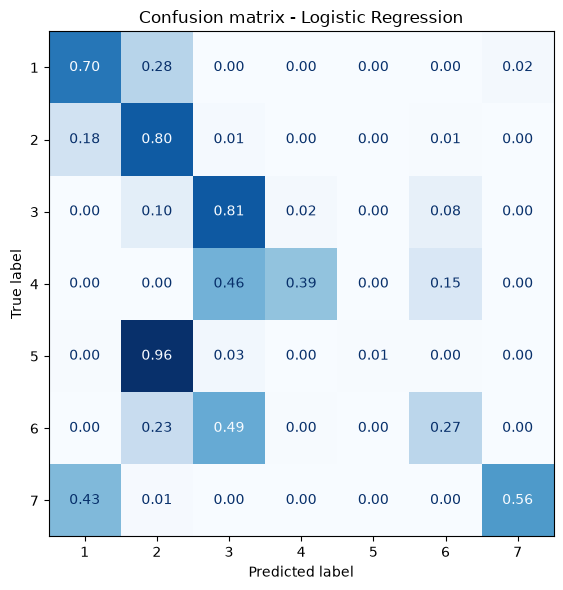

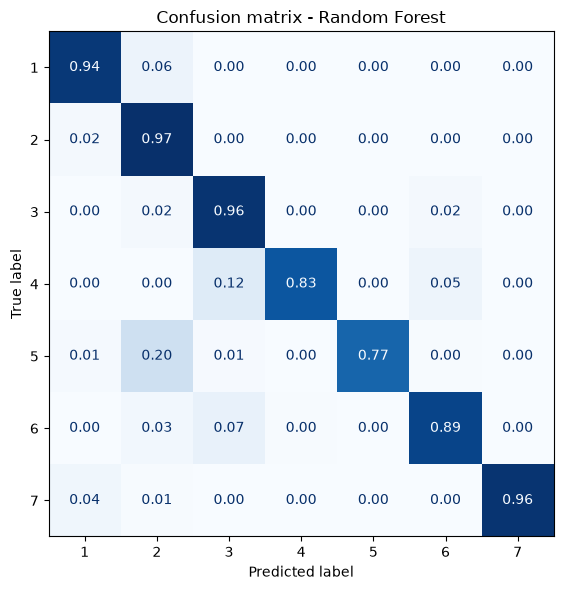

In [36]:
plot_confusion("Logistic Regression", y_dev, lr_y_pred, save_path="../results/cm_logreg.png")
plot_confusion("Random Forest", y_dev, rf_y_pred, save_path="../results/cm_rf.png")

**Observations (confusion matrices, original class names 1-7)**
- Logistic Regression: 96% of class 5 is predicted as class 2, and 49% of class 6 is predicted as class 3. Class 7 is often confused with class 1 (43%). Classes 1 and 2 are also mixed (28% and 18%).
- Random Forest: the diagonal is above 0.77 for every class. The main errors are class 5 predicted as class 2 (20%) and class 4 predicted as class 3 (12%).

## 7. Summary

| Model | Accuracy | Macro F1 |
|---|---|---|
| Majority class | 0.488 | 0.094 |
| Logistic Regression | 0.725 | 0.526 |
| Random Forest | 0.954 | 0.923 |

**Takeaways**
- Macro F1 is the main metric. The small classes are where models fail.
- The linear model cannot separate the classes well, so a neural network with hidden layers should improve on it clearly.
- Random Forest is a strong reference. The neural network target is to get close to its macro F1.

**Next:** `03_nn_experiments.ipynb` - Keras models and the ablation study.